# Big Data Analysis
## Machine learning in Spark: is this property haunted?

Goal for today:
- Understand what a classification model does: learn from labelled examples, then predict for new ones
- Explore a dataset before modelling (EDA): missing values, outliers, correlations
- Prepare features: one-hot encoding, feature scaling, one feature vector
- Split the data into a training set and a test set, and say why we need both
- Train and compare models in Spark ML: logistic regression, decision tree, random forest, gradient-boosted trees
- Read a confusion matrix and the evaluation metrics built from it (accuracy, recall, precision, F1, AUC)
- Recognise overfitting: a model that memorises instead of learning

How to use this notebook:
- Run it in Databricks (Free Edition), top to bottom
- Read each picture before the code below it
- Most code cells are ready to run; you write code only in the exercises (cells with `# TODO`)
- Exercises are labelled Core or Practice
- The optional challenge at the very end is not part of the class: it is for students who want to explore text features for the project

Dataset
- `haunted_houses.parquet`: the National Anomalous Property Register (NAPR), kept by HMSPIA, a (fictional) government agency that investigates properties behaving in ways that physics cannot explain. Its budget is mostly spent on tea and biscuits
- 5,000 properties, 26 columns: numbers (owl hoots per night, dread score, visitors who disappeared, ...), yes/no flags (fog, bell tower, moor nearby, ...), categories (type of phenomenon, type of ghost) and free text (what the estate agent, the cat and the vicar said)
- The column we want to predict is `haunted` (true or false)

___

## 1) The big idea: learning from examples

HMSPIA investigators have already closed thousands of files. For each property they wrote down what they observed (dread, owl hoots, fog, ...) and their final decision: haunted or not.

An experienced investigator develops a feeling for it: "fog, a bell tower and three missing visitors... this one is haunted". **Machine learning** builds that feeling from the data: a program looks at many past examples, finds the rules that connect the observations with the decision, and then applies those rules to properties it has never seen.

When the answer is a category (here: haunted yes or no), this is called **classification**. When the answer is a number (for example a price), it is called **regression**.

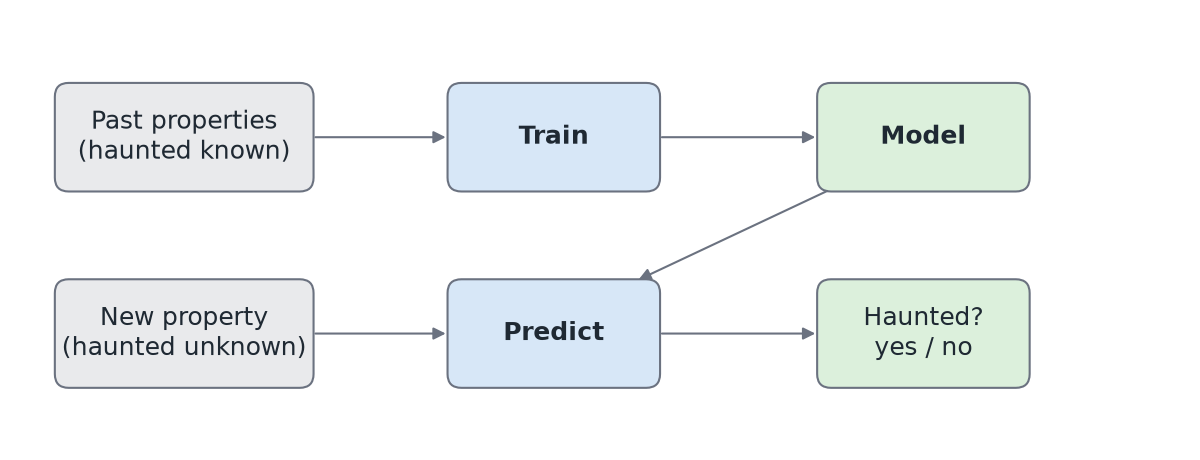

The words we will use all session:

| Word | Plain meaning | In this notebook |
|---|---|---|
| Feature | an input column the model may look at | `dread`, `foggy`, `owl_hoots`, ... |
| Label (or target) | the column we want to predict | `haunted` |
| Training | letting the model find rules from examples where the label is known | `.fit(training)` |
| Model | the rules it found, ready to be applied | `lr_model`, `dt_model`, ... |
| Prediction | the model's guess for a row | the `prediction` column |
| Test set | rows hidden during training, used to grade the model | `test` |

Here are four real rows of the register. The grey columns are features; the green one is the label:

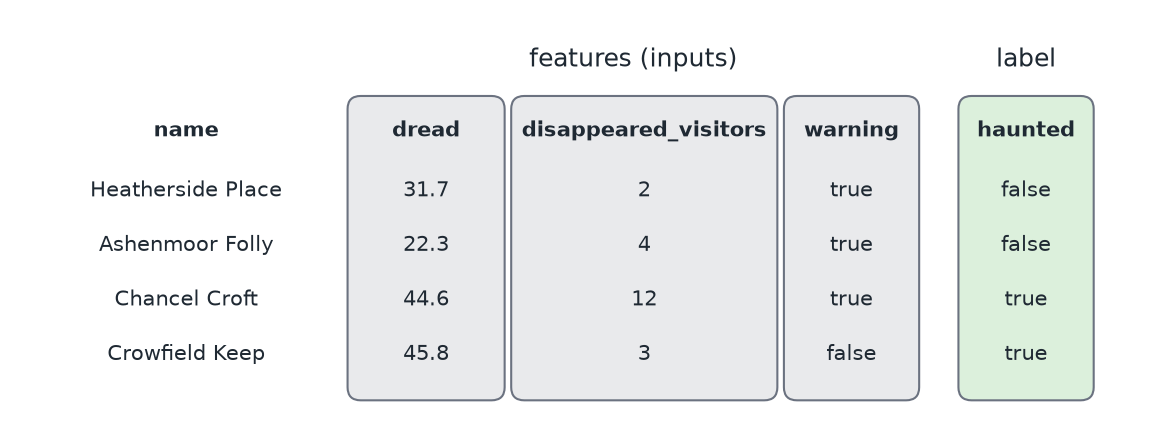

What should you notice?
- No single column decides. Crowfield Keep is haunted with only 3 missing visitors and no warning; Heatherside Place had a warning and is not haunted
- A model is useful exactly because it **combines** many weak clues

### 1.1 Spark ML in two verbs

Spark ML (the `pyspark.ml` library) follows one pattern for every step, from encoding a column to training a model:

| Verb | What it does | Kitchen analogy |
|---|---|---|
| `.fit(df)` | looks at the data and learns something (a list of categories, an average, the rules of a model); returns a fitted object | tasting the ingredients and writing the recipe |
| `.transform(df)` | applies what was learned and returns the DataFrame with new columns | cooking with the recipe |

As always in Spark, the data stays spread over the executors; only small results (scores, counts) come back to the driver.

___

## 2) Setup

The first cell installs the few extra Python libraries we need. It takes about a minute.

In [ ]:
# 2.1 Extra libraries (pyod is used for outlier detection in section 4.3)
%pip install plotly matplotlib seaborn scikit-learn mlflow "nbformat>=4.2.0" pyod pyarrow --quiet

In [ ]:
# 2.2 Imports, Spark session and data path
import os

import matplotlib.pyplot as plt
import seaborn as sns
import mlflow

from pyspark.sql import SparkSession
from pyspark.sql import functions as F
from pyspark.sql.functions import col, count, when, lit, size, split
from pyspark.sql.types import IntegerType

from pyspark.ml.stat import Correlation
from pyspark.ml.feature import StringIndexer, OneHotEncoder, VectorAssembler, StandardScaler
from pyspark.ml.classification import LogisticRegression
from pyspark.ml.evaluation import BinaryClassificationEvaluator

spark = SparkSession.builder.appName("HMSPIA_NAPR_ML_ISPA").getOrCreate()

# The data file sits next to this notebook, so no path needs editing
DATA_PATH = f"{os.getcwd()}/haunted_houses.parquet"
TARGET = "haunted"

In [ ]:
# 2.3 Load the register and look at the column types
properties = spark.read.parquet(DATA_PATH)

properties.printSchema()
print("Rows:", properties.count())

Check: you should see 26 columns and `Rows: 5000`.

The columns come in four kinds:

| Kind | Columns |
|---|---|
| Identifiers | `unique_haunt_identifier`, `name`, `location` |
| Numbers | `construction_date`, `owl_hoots` (per night), `villagers_count`, `disappeared_visitors`, `dread` (a score), `tripadvisor_stars`, `insurance_exclusion_clauses` |
| Yes/no flags | `warning` (locals warned visitors), `teenage_group_disappearance`, `foggy`, `belltower`, `moor_nearby`, and the label `haunted` |
| Categories and text | `phenomenon_type`, `ghost`, `cursed_ground_type`, `previous_owners_fate`, `archaeology_report_status`, `sightings` (years, separated by `|`), and four free-text columns |

In [ ]:
# 2.4 A first look, one group of columns at a time
properties.select("name", "location", "construction_date", "phenomenon_type", "ghost").show(3, truncate=30)

properties.select("owl_hoots", "villagers_count", "disappeared_visitors",
                  "dread", "insurance_exclusion_clauses").show(3)

properties.select("warning", "teenage_group_disappearance", "foggy",
                  "belltower", "moor_nearby", "haunted").show(3)

Discussion: `dread` is a number between 20 and 70. Who measured it, and how? When a column is a score given by a person, what could make two investigators give different scores to the same property?

___

## 3) Missing values

Spark ML models refuse rows with empty (`null`) values, so we check first.

In [ ]:
# 3.1 Number of nulls in every column
properties.select(
    [count(when(col(c).isNull(), c)).alias(c) for c in properties.columns]
).show(vertical=True)

What should you notice?
- Only three text columns have missing values: `cat_behaviour` (2), `vicar_response` (1) and `most_recent_excuse` (11)
- All of them together are 13 rows out of 5,000, so we simply drop them

In [ ]:
# 3.2 Drop the rows with any null value
properties = properties.na.drop()
print("Rows left:", properties.count())

Check: `Rows left: 4987`.

Discussion: dropping 13 rows out of 5,000 is harmless. What if a column were empty in 30% of the rows, and those rows were mostly the haunted ones? What would the model learn then?

___

## 4) Exploratory Data Analysis (EDA)

**Exploratory Data Analysis (EDA)** is the first look at a dataset before any model: what the columns contain, how values are spread, which values are strange, and how columns relate to each other and to the label. Its findings guide every later decision (which rows to drop, which features to build, which model to try).

### 4.1 Summary statistics

`describe()` gives count, mean, standard deviation, min and max for each column.

In [ ]:
# 4.1 Summary of the main numeric columns
numeric_cols = ["owl_hoots", "villagers_count", "disappeared_visitors",
                "dread", "insurance_exclusion_clauses"]

properties.select(numeric_cols).describe().show()

## Exercise 1 (Core): how many properties are haunted?

`groupBy()` splits the rows into groups and `count()` counts each group. `withColumn()` adds a new column computed from others, and `F.round()` rounds it.

**Goal:** Count the properties per value of `haunted`, and add a column `pct` with the percentage of all properties in each group (rounded to 1 decimal).

**Concepts:** `groupBy()`, `count()`, `withColumn()`, `F.col()`, `F.round()`, `orderBy()`

**Expected output:** 2 rows with columns `haunted`, `count`, `pct`: `false` 4239 (85.0%) and `true` 748 (15.0%).

In [ ]:
# F (pyspark.sql.functions) was imported in 2.2

# TODO: Store the total number of rows of `properties` in a variable `total`.
# TODO: Group `properties` by "haunted" and count the rows of each group.
# TODO: Add a column "pct" = count / total * 100, rounded to 1 decimal with F.round().
# TODO: Order by "haunted" and show the result.

Discussion: a lazy "model" that always answers "not haunted", without looking at anything, would be right 85% of the time. Keep this number in mind: any real model must do better than that, and as we will see, being right 85% of the time can still mean being useless.

When one class is much rarer than the other, as here, the data is called **imbalanced**.

### 4.2 Does dread differ between haunted and non-haunted properties?

The table summarises `dread` for each group with its quartiles: 25% of the values are below `q1`, 50% below the `median`, 75% below `q3`. The histogram draws the same comparison as a picture.

In [ ]:
# 4.2a Dread per group
properties.groupBy("haunted").agg(
    F.min("dread").alias("min"),
    F.percentile_approx("dread", 0.25).alias("q1"),
    F.percentile_approx("dread", 0.50).alias("median"),
    F.percentile_approx("dread", 0.75).alias("q3"),
    F.max("dread").alias("max"),
    F.round(F.mean("dread"), 1).alias("mean"),
).orderBy("haunted").show()

In [ ]:
# 4.2b Histogram of dread, one colour per group
# Only 2 columns of a few thousand rows come back to the driver: small enough to plot
dread_pdf = properties.select("dread", "haunted").toPandas()

fig, ax = plt.subplots(figsize=(8, 4))
for value, colour, label in [(False, "#9AA5B1", "not haunted"), (True, "#3E8E5A", "haunted")]:
    ax.hist(dread_pdf.loc[dread_pdf["haunted"] == value, "dread"], bins=30,
            density=True, alpha=0.6, color=colour, label=label)
ax.set_xlabel("dread")
ax.set_ylabel("density")
ax.legend(frameon=False)
plt.show()

What should you notice?
- The haunted group (green) sits further to the right: higher dread on average
- The two groups overlap a lot: many non-haunted properties are scarier than some haunted ones. One column is not enough to decide; the model will have to combine several
- `density=True` scales each group so its bars cover the same area. Without it, the non-haunted group (more than 5 times bigger) would hide the haunted one

### 4.3 Outliers

An **outlier** is a row whose values are far from the rest of the data. It can be:
- an **error**: a typo of 900 owl hoots instead of 90, a sensor failure, a wrong unit
- a **genuine extreme case**: a real property that is simply much scarier than all the others

Outliers matter because some models are pulled strongly by a few extreme rows, and errors teach the model things that are not true. Checking one column at a time (for example "more than 3 standard deviations from the mean") misses rows that are only strange in **combination** (many villagers *and* many owl hoots).

#### Outlier detection with Isolation Forest

An **Isolation Forest** looks at all numeric columns together. The idea is the "Guess who?" game: to single out one property, ask random yes/no questions ("more than 60 hoots?", "fewer than 300 villagers?"). An ordinary property hides in the crowd and needs many questions; an odd one is isolated after very few. The forest repeats this with many random question sequences: the fewer questions needed on average, the higher the **outlier score**.

The model comes from the `pyod` library, which works on pandas DataFrames. `applyInPandas` sends the data to an executor as a pandas DataFrame, runs the model there, and returns a Spark DataFrame with two new columns: `outlier_score` and `is_outlier`. `contamination=0.05` means "flag the 5% most unusual properties".

In [ ]:
# 4.3 Score every property with an Isolation Forest, then drop the flagged ones
import pandas as pd
from pyspark.sql.types import StructType, StructField, DoubleType

OUTLIER_FEATURES = numeric_cols

outlier_schema = StructType(
    properties.schema.fields
    + [StructField("outlier_score", DoubleType(), True),
       StructField("is_outlier", IntegerType(), True)]
)

def score_with_isolation_forest(pdf: pd.DataFrame) -> pd.DataFrame:
    # Runs on an executor
    from pyod.models.iforest import IForest
    clf = IForest(contamination=0.05, random_state=42)
    clf.fit(pdf[OUTLIER_FEATURES].values)
    pdf = pdf.copy()
    pdf["outlier_score"] = clf.decision_scores_      # higher = more unusual
    pdf["is_outlier"] = clf.labels_.astype(int)      # 1 = flagged
    return pdf

# repartition(1): score all rows together, so "5%" means 5% of the whole register
properties_scored = (
    properties.repartition(1)
    .groupby()
    .applyInPandas(score_with_isolation_forest, schema=outlier_schema)
)

properties_scored.filter(col("is_outlier") == 1) \
    .select(["name"] + OUTLIER_FEATURES + ["outlier_score", "haunted"]) \
    .orderBy(col("outlier_score").desc()) \
    .show(5, truncate=30)

properties = properties_scored.filter(col("is_outlier") == 0).drop("outlier_score", "is_outlier")
print("Rows left after removing outliers:", properties.count())

Check: about 250 properties are flagged, and about 4,737 rows are left.

Discussion: look at the flagged rows above. Are they errors, or just the most extreme (and maybe the most interesting) properties? Removing outliers is a decision, not an automatic step. When would you remove them, and when would you keep them?

### 4.4 Correlation analysis

The **Pearson correlation coefficient** (`r`) measures how strongly two numeric columns move together **along a straight line**:
- `r = +1`: when one goes up, the other always goes up, on a perfect line
- `r = -1`: when one goes up, the other always goes down, on a perfect line
- `r = 0`: no straight-line relationship

A rough guide: below 0.3 (in absolute value) is weak, 0.3 to 0.7 moderate, above 0.7 strong. Here are two real pairs from the register:

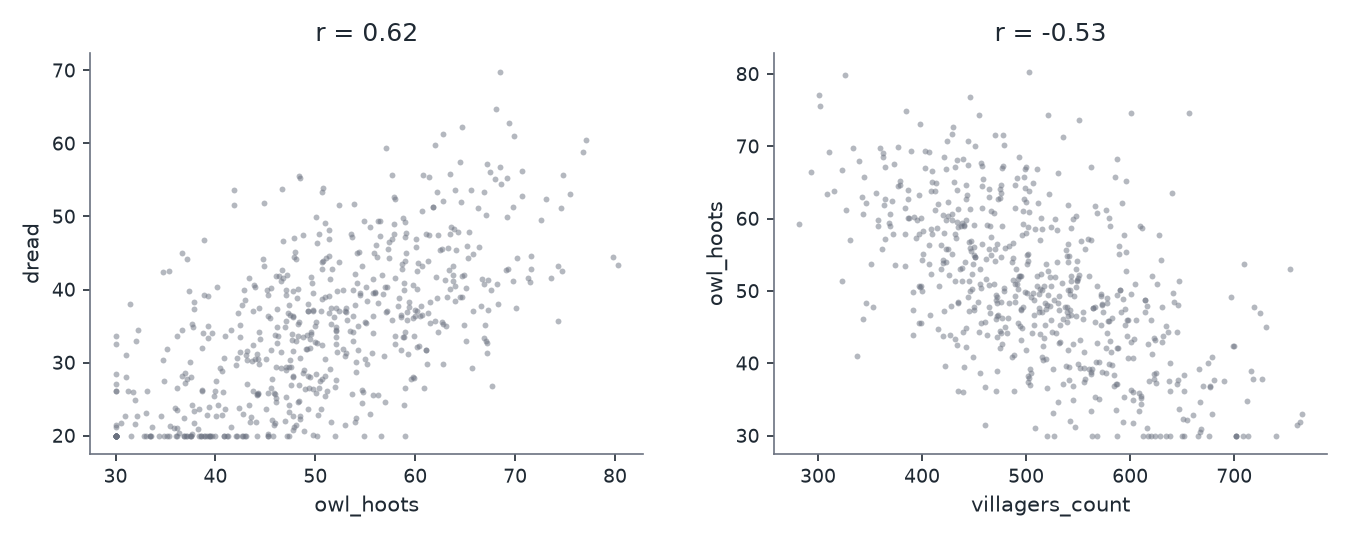

What should you notice?
- Left: properties with more owl hoots tend to have more dread, but the cloud is wide. `r = 0.62` is a moderate positive correlation, not a rule that holds for every property
- Right: properties with more villagers tend to have fewer owl hoots (`r = -0.53`)

Two cautions:
- `r` only sees straight lines. A U-shaped relationship can give `r` close to 0 even when the link is strong, so always look at the scatter plot too
- **Correlation is not causation.** Owls probably do not create dread; both may come from something else, such as a remote, wooded location

#### Why correlation matters for machine learning

When two **features** are strongly correlated with each other, they carry almost the same information. This is called **multicollinearity**:
- The model cannot tell which of the two deserves the credit, so it may split it between them in an arbitrary way
- In logistic regression this makes the weights unstable (they can change a lot, or even flip sign, with a slightly different sample) and hard to interpret, even when the predictions stay good
- Tree-based models are much less affected
- A common rule of thumb: if two features have `|r|` above about 0.8, keep only one of them, or combine them into one

The **correlation matrix** below shows `r` for every pair of numeric columns at once. The diagonal is always 1 (each column with itself).

> Spark computes correlations on a single "vector" column, so the five columns are first packed into one (section 7 explains how). Only the small 5 x 5 result comes back to the driver to be drawn.

In [ ]:
# 4.4 Pearson correlation matrix of the numeric columns
assembler_corr = VectorAssembler(inputCols=numeric_cols, outputCol="corr_features")
df_corr = assembler_corr.transform(properties).select("corr_features")
pearson_matrix = Correlation.corr(df_corr, "corr_features", "pearson").collect()[0][0]

fig, ax = plt.subplots(figsize=(8, 6))
sns.heatmap(pearson_matrix.toArray(), annot=True, fmt=".2f", cmap="RdBu_r", vmin=-1, vmax=1,
            xticklabels=numeric_cols, yticklabels=numeric_cols, ax=ax)
plt.tight_layout()
plt.show()

What should you notice?
- The strongest pair is `owl_hoots` and `dread` (about 0.6); `villagers_count` is negatively correlated with both (about -0.5)
- No pair goes above 0.8, so multicollinearity is not a serious problem here and we keep all five columns

Discussion: `dread` is a score given by investigators. Could an investigator who hears many owls at night give a higher dread score because of it? What would that mean for the correlation we see?

___

## 5) Feature engineering

**Feature engineering** means preparing the columns the model will learn from: creating new features from existing ones, and turning every feature into numbers. A model only computes with numbers (it multiplies, adds and compares them), so a text value like `"poltergeist"` or `true` cannot be used as it is.

Our features come in three kinds, and each needs a different treatment:
- **numbers**: ready, but on very different scales (section 6)
- **yes/no flags**: turn true/false into 1/0
- **categories**: one-hot encoding

### 5.1 Creating new features

Sometimes the most useful feature is not in the table but can be computed from it:
- `property_age` = 2026 - `construction_date`: an age is easier to interpret than a year
- `sightings_count` = number of years listed in `sightings` (a text like `"1734|1797|1827"` becomes 3)

In [ ]:
# 5.1 Property age and number of recorded sightings
CURRENT_YEAR = 2026
properties = properties.withColumn("property_age", lit(CURRENT_YEAR) - col("construction_date"))
properties = properties.withColumn("sightings_count", size(split(col("sightings"), r"\|")))

properties.select("construction_date", "property_age", "sightings", "sightings_count").show(4, truncate=40)

### 5.2 Encoding categorical features: one-hot encoding

Categorical features come in two kinds:
- **Nominal**: categories with no natural order. `phenomenon_type` (haunting, poltergeist, ...) and `ghost` (vengeful widow, spectral coachman, ...): no category is "more" than another
- **Ordinal**: categories with a natural order, like `tripadvisor_stars` (1 to 5) or small / medium / large. These can often stay as numbers, because the order means something

#### Why not just give each category a number?

The simplest idea is **label encoding**: haunting = 0, frequent nightmares = 1, hallucinations = 2, poltergeist = 3 (Spark numbers them by frequency, the most common first). For a nominal feature this invents information that is not in the data:

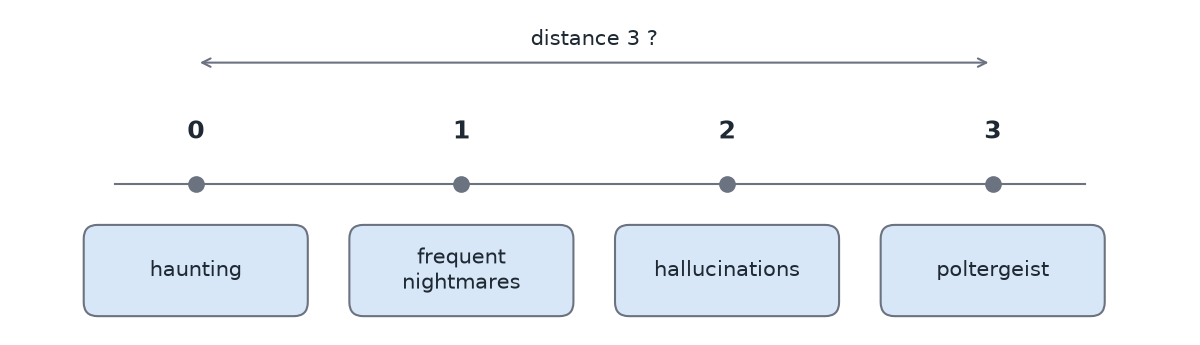

- **A fake order**: the model reads poltergeist (3) as "more" than haunting (0)
- **Fake distances**: haunting looks closer to frequent nightmares (distance 1) than to poltergeist (distance 3)
- **A single direction**: logistic regression gives the column one weight, so it can only say "the higher the number, the more (or less) likely haunted". It cannot say "poltergeists and hauntings are likely, nightmares are not", because that does not follow the numbering

#### The solution: one yes/no column per category

**One-hot encoding** replaces the category column with one yes/no (1/0) column per category, often called **dummy variables**. In each row exactly one of them is 1:

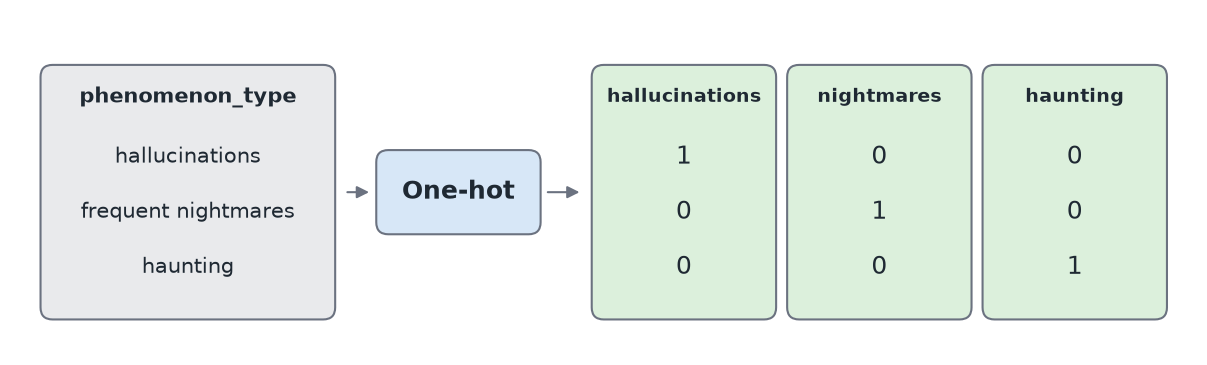

Now every category gets its own weight in the model, and no category is closer to or "bigger" than another.

Things to know about one-hot encoding:
- **It adds many columns**: one per category. `phenomenon_type` (18 categories) and `ghost` (42) become about 60 columns. A column with thousands of categories would explode the number of features; that is one reason we do not encode `name` (about 2,000 different names) or `location` (about 240 places), which describe individual properties rather than general patterns
- **One column is dropped**: if all the other columns are 0, the remaining category is known, so its column adds no information. Spark drops it by default
- **Most values are 0**, so Spark stores the result as a **sparse vector**, writing only where the 1 is: `(18,[2],[1.0])` means "18 positions, position 2 is 1, all others are 0"

In Spark it takes two steps:
1. `StringIndexer` gives each category a number (label encoding, only as an intermediate step)
2. `OneHotEncoder` turns that number into the yes/no positions

In [ ]:
# 5.2 Categories -> index -> one-hot vector
indexer = StringIndexer(
    inputCols=["phenomenon_type", "ghost"],
    outputCols=["phenomenon_idx", "ghost_idx"],
    handleInvalid="keep",          # a category never seen before gets its own index
)
properties = indexer.fit(properties).transform(properties)

encoder = OneHotEncoder(
    inputCols=["phenomenon_idx", "ghost_idx"],
    outputCols=["phenomenon_vec", "ghost_vec"],
)
properties = encoder.fit(properties).transform(properties)

properties.select("phenomenon_type", "phenomenon_idx", "phenomenon_vec").show(5, truncate=False)

What should you notice?
- `phenomenon_idx` is the intermediate number; `phenomenon_vec` is the one-hot vector
- All rows with the same category have the 1 in the same position

### 5.3 Yes/no features

Yes/no flags are already "one-hot" with a single column: we only turn `true`/`false` into 1/0. The label `haunted` is converted too, because Spark ML expects a numeric label.

In [ ]:
# 5.3 Yes/no flags (and the label) -> 1/0
bool_cols = ["warning", "teenage_group_disappearance", "foggy", "belltower", "moor_nearby"]
for c in bool_cols + [TARGET]:
    properties = properties.withColumn(c, col(c).cast(IntegerType()))

properties.select(bool_cols + [TARGET]).show(3)

___

## 6) Feature scaling

Our numeric features are measured in very different units and ranges: `villagers_count` goes from about 200 to 800 people, `disappeared_visitors` from 0 to 20, `property_age` from about 80 to 830 years. **Feature scaling** puts them on a common scale.

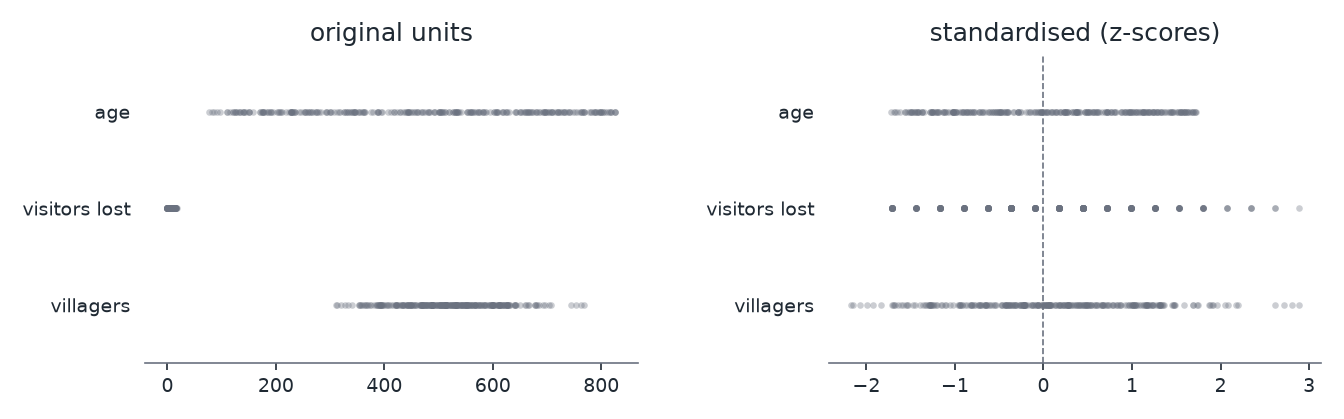

### 6.1 Why scale?

- **Models that add up weighted features** (like logistic regression) or **measure distances between rows** (like clustering) are affected by units. Without scaling, the distance between two properties is almost entirely their difference in villagers or age, because those numbers are hundreds of times bigger than the number of lost visitors
- **Comparable weights**: a weight "per villager" and a weight "per lost visitor" cannot be compared. After scaling, every weight means "the effect of one standard deviation", so we can see which features matter most (section 9.4)
- **Faster, more stable training**: the algorithms that adjust the weights step by step work better when all columns have similar sizes

Not every model needs it: **decision trees** and the models built from them only compare one column with a threshold ("dread > 40?"), so the units do not matter to them.

### 6.2 Standardisation (z-scores)

The most common method is **standardisation**: for each column, subtract its mean and divide by its standard deviation.

```
z = (value - mean) / standard deviation
```

After standardisation every column has mean 0 and standard deviation 1, and a value says "how many standard deviations above (+) or below (-) the average" a property is. With the register's values:
- 600 villagers: (600 - 508) / 91 = about **+1.0**
- 12 lost visitors: (12 - 6.3) / 3.7 = about **+1.5**

In original units, 600 looks much "bigger" than 12. After scaling we see the opposite: 12 lost visitors is more unusual than 600 villagers.

> Another method is **min-max scaling** (`MinMaxScaler` in Spark), which squeezes each column between 0 and 1. It is simple, but a single outlier can squash all the other values together.

In Spark, `StandardScaler` works on one vector column, so the numeric columns are first packed together with `VectorAssembler` (section 7 explains it in full).

In [ ]:
# 6.2 Pack the numeric features into one vector, then standardise it
feature_cols_numeric = ["property_age", "sightings_count", "owl_hoots", "villagers_count",
                        "disappeared_visitors", "dread", "insurance_exclusion_clauses"]

assembler_num = VectorAssembler(inputCols=feature_cols_numeric, outputCol="numeric_features")
properties = assembler_num.transform(properties)

scaler = StandardScaler(inputCol="numeric_features", outputCol="numeric_scaled",
                        withMean=True, withStd=True)
properties = scaler.fit(properties).transform(properties)

properties.select("numeric_features", "numeric_scaled").show(3, truncate=False)

What should you notice?
- `numeric_features` mixes values in the hundreds with values below 10
- In `numeric_scaled` every value is small, mostly between -3 and +3, with 0 meaning "average"

> `fit` learns each column's mean and standard deviation, `transform` applies the formula. Strictly, the scaler should learn them from the **training rows only** (section 8), otherwise a little information from the test rows leaks into training. Next week, pipelines will do this properly.
>
> Spark's `LogisticRegression` also standardises internally while it trains, but it reports the weights back in the original units. Scaling ourselves makes the weights comparable, and many other models need it.

___

## 7) Assembling the feature vector

Spark ML models expect **all** features in a single column, as a list of numbers called a **feature vector**. `VectorAssembler` builds it by placing the columns one after another: the scaled numbers, then the 0/1 flags, then the one-hot positions.

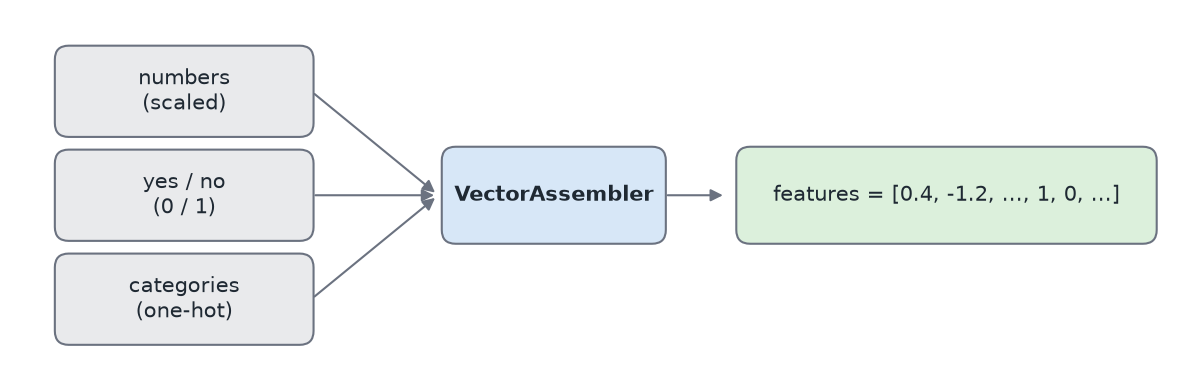

In [ ]:
# 7.1 One feature vector per property
feature_cols_boolean = bool_cols
feature_cols_categorical = ["phenomenon_vec", "ghost_vec"]

assembler_all = VectorAssembler(
    inputCols=["numeric_scaled"] + feature_cols_boolean + feature_cols_categorical,
    outputCol="features",
)
data = assembler_all.transform(properties).select("features", TARGET)

data.show(3, truncate=80)

What should you notice?
- Each property is now one row with a `features` vector (about 70 positions: 7 numbers, 5 flags and one position per category) and a `haunted` label
- From here on, the models only see these two columns

___

## 8) Train/test split

A student who memorises last year's exam can get 20/20 on that exam and still fail a new one. To know whether a model has really learned, we grade it on rows it has **never seen**: we hide 30% of the data during training and use them only at the end.

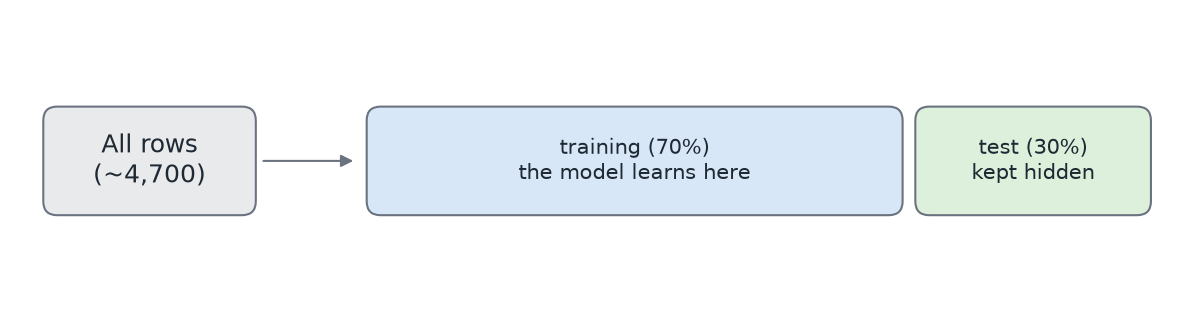

`randomSplit([0.7, 0.3], seed=42)` splits the rows at random. The `seed` makes the random choice repeatable: everyone gets the same split.

In [ ]:
# 8.1 Split 70 / 30
training, test = data.randomSplit([0.7, 0.3], seed=42)
print("Training rows:", training.count())
print("Test rows:    ", test.count())

## Exercise 2 (Core): the same balance in both sets?

`groupBy()` and `count()` work on any DataFrame, including `training` and `test`.

**Goal:** Count how many haunted (1) and non-haunted (0) properties there are in `training` and in `test`, and check that the share of haunted properties is similar in both.

**Concepts:** `groupBy()`, `count()`, `orderBy()`

**Expected output:** two small tables of 2 rows each (`haunted`, `count`). Training has about 70% of the rows, and about 13% of the properties are haunted in both sets.

In [ ]:
# TODO: Group `training` by TARGET, count, order by TARGET and show.
# TODO: Do the same for `test`.
# TODO (optional): compute the share of haunted properties in each set.

Discussion: why does it matter that the test set has about the same share of haunted properties as the training set? What could go wrong with a very small test set?

___

## 9) Worked example: logistic regression

Despite its name, **logistic regression** is a classification model. It works like a scoring sheet: each feature gets a weight (a warning: +1 point, many villagers: -0.1 points, ...). The points are added up and turned into a probability between 0 and 1. If the probability of "haunted" is above 0.5 (the **decision threshold**), the prediction is 1.

Training = finding the weights that make the sheet agree as much as possible with the past decisions.

### 9.1 Training and predicting

In [ ]:
# 9.1 Train on the training set, predict on the test set
lr = LogisticRegression(featuresCol="features", labelCol=TARGET)
lr_model = lr.fit(training)

test_preds = lr_model.transform(test)
test_preds.select(TARGET, "probability", "prediction").show(8, truncate=False)

What should you notice?
- `transform` added new columns. `probability` holds two numbers: the chance of "not haunted" and of "haunted" (they add up to 1)
- `prediction` is 1 when the second number is above 0.5, otherwise 0
- On the test set we know the real answer (`haunted`), so we can count right and wrong guesses

### 9.2 The confusion matrix

A **confusion matrix** counts the predictions in four boxes, comparing what the model said with the truth:

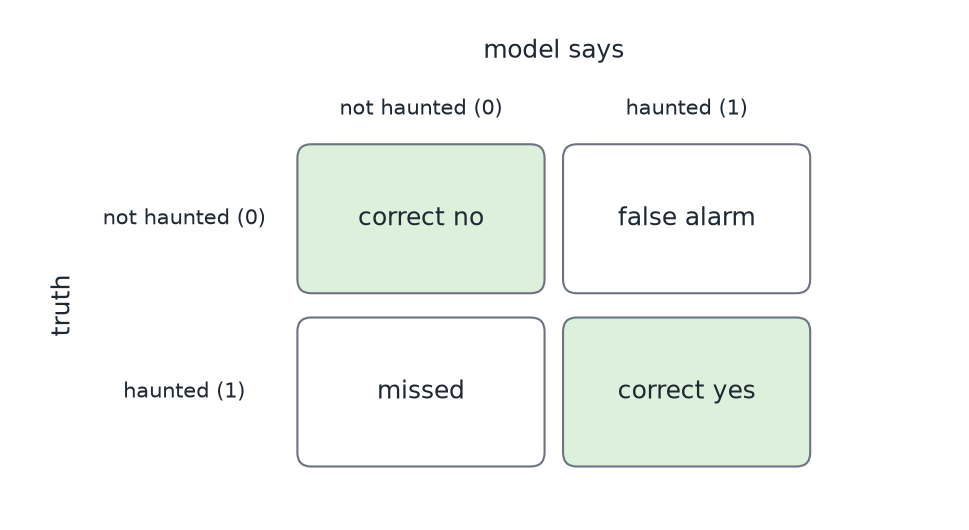

In ML vocabulary the four boxes are called **true negatives** (correct no), **false positives** (false alarm), **false negatives** (missed) and **true positives** (correct yes). "Positive" is simply the class we are looking for: haunted.

In [ ]:
# 9.2 Confusion matrix on the test set (rows = truth, columns = prediction)
test_preds.groupBy(TARGET).pivot("prediction", [0.0, 1.0]).count() \
    .na.fill(0).orderBy(TARGET).show()

### 9.3 Evaluation metrics

Think of a smoke alarm. **Recall** asks "of all the real fires, how many did it catch?". **Precision** asks "of all the times it rang, how many were real fires?".

| Metric | Question it answers | From the matrix |
|---|---|---|
| Accuracy | what share of all guesses were right? | (TP + TN) / all |
| Recall | of the haunted properties, how many did we find? | TP / (TP + FN) |
| Precision | when we said "haunted", how often were we right? | TP / (TP + FP) |
| F1 | one number that balances recall and precision | 2 x precision x recall / (precision + recall) |
| F1 (macro) | F1 for "haunted" and F1 for "not haunted", averaged, so both classes count equally | (F1 yes + F1 no) / 2 |
| AUC | does the model give haunted properties higher probabilities than the others, whatever the threshold? 0.5 = coin toss, 1 = perfect | `BinaryClassificationEvaluator` |

The function below computes all of them from a DataFrame of predictions. We will reuse it for every model.

In [ ]:
# 9.3 All evaluation metrics from a DataFrame of predictions
def scores(preds):
    rows = preds.groupBy(TARGET, "prediction").count().collect()
    c = {(int(r[TARGET]), int(r["prediction"])): r["count"] for r in rows}
    tn, fp = c.get((0, 0), 0), c.get((0, 1), 0)   # truth 0: correct no, false alarm
    fn, tp = c.get((1, 0), 0), c.get((1, 1), 0)   # truth 1: missed, correct yes

    f1_yes = 2 * tp / (2 * tp + fp + fn) if tp else 0.0
    f1_no = 2 * tn / (2 * tn + fn + fp) if tn else 0.0
    return {
        "accuracy": (tp + tn) / (tp + tn + fp + fn),
        "recall": tp / (tp + fn) if (tp + fn) else 0.0,
        "precision": tp / (tp + fp) if (tp + fp) else 0.0,
        "f1_macro": (f1_yes + f1_no) / 2,
        "auc": BinaryClassificationEvaluator(labelCol=TARGET, rawPredictionCol="probability").evaluate(preds),
    }

for name, value in scores(test_preds).items():
    print(f"{name:10s} {value:.3f}")

What should you notice?
- Accuracy looks high. Now compare it with the lazy "always not haunted" answer from Exercise 1
- Recall is much lower: the model misses a large share of the haunted properties
- With imbalanced data, never judge a model on accuracy alone

Discussion: for HMSPIA, which mistake is worse: a false alarm (a team visits a normal house) or a missed haunting (nobody visits a haunted one)? Which metric should they watch most?

### 9.4 What did the model learn?

Because the numbers were scaled (section 6), the weights of the numeric features can be compared with each other. A positive weight pushes towards "haunted", a negative one away from it.

In [ ]:
# 9.4 Weights of the numeric features and flags (the first 12 positions of the vector)
import plotly.graph_objs as go

coef_labels = feature_cols_numeric + feature_cols_boolean
coef_values = [float(v) for v in lr_model.coefficients[: len(coef_labels)]]
pairs = sorted(zip(coef_labels, coef_values), key=lambda x: x[1])

fig = go.Figure(go.Bar(x=[v for _, v in pairs], y=[n for n, _ in pairs], orientation="h"))
fig.update_layout(title="Logistic regression weights (positive = more likely haunted)",
                  xaxis_title="weight")
fig.show()

What should you notice?
- The yes/no flags (warning, a group of teenagers that disappeared, fog, bell tower, moor) and `disappeared_visitors` push towards "haunted"
- Weights close to 0 belong to features the model barely uses

Discussion: `warning` has a large positive weight. Does a warning from the locals **cause** a haunting? What else could explain the link?

___

## 10) Model comparison

### 10.1 One function for every model

`evaluate_model()` repeats section 9 in one call: it scores a fitted model on the training set **and** on the test set, shows the test confusion matrix, and adds a row to the `results` table for the final comparison.

It also records every model in **MLflow**, the experiment tracking tool built into Databricks: each call becomes a *run* with its settings (e.g. `maxDepth`) and its metrics, so nothing depends on our memory. You can see the runs in the Experiments panel (flask icon on the right edge of the notebook); section 11 shows them as a table.

In [ ]:
# 10.1 MLflow experiment (in your home folder) and the evaluation helper
user = spark.sql("SELECT current_user()").first()[0]
EXPERIMENT_NAME = f"/Users/{user}/lab10_ISPA_haunted_properties"
mlflow.set_experiment(EXPERIMENT_NAME)

results = []
HYPERPARAMS = {"maxDepth", "numTrees", "maxIter", "stepSize", "regParam", "seed"}

def evaluate_model(model_name, fitted_model, train_data, test_data):
    train_s = scores(fitted_model.transform(train_data))
    test_preds = fitted_model.transform(test_data)
    test_s = scores(test_preds)

    print(model_name)
    print(f"  train: AUC {train_s['auc']:.3f} | F1 (macro) {train_s['f1_macro']:.3f}")
    print(f"  test:  AUC {test_s['auc']:.3f} | F1 (macro) {test_s['f1_macro']:.3f}"
          f" | recall {test_s['recall']:.3f} | precision {test_s['precision']:.3f}"
          f" | accuracy {test_s['accuracy']:.3f}")
    print("  test confusion matrix (rows = truth, columns = prediction):")
    test_preds.groupBy(TARGET).pivot("prediction", [0.0, 1.0]).count() \
        .na.fill(0).orderBy(TARGET).show()

    with mlflow.start_run(run_name=model_name):
        mlflow.log_params({p.name: fitted_model.getOrDefault(p)
                           for p in fitted_model.params if p.name in HYPERPARAMS})
        mlflow.set_tag("model_family", type(fitted_model).__name__)
        for k, v in train_s.items():
            mlflow.log_metric(f"train_{k}", v)
        for k, v in test_s.items():
            mlflow.log_metric(f"test_{k}", v)

    results.append((model_name, test_s["auc"], test_s["f1_macro"], test_s["recall"],
                    train_s["auc"], train_s["f1_macro"]))

# The logistic regression from section 9 is the first entry
evaluate_model("Logistic Regression", lr_model, training, test)

Check: you should see the training and test metrics of the logistic regression, and its confusion matrix (the same as in 9.2).

### 10.2 Decision trees, hyperparameters and overfitting

A **decision tree** is a chain of yes/no questions, like the flowchart below. Training chooses which question to ask at each step, and where to put the threshold, so that each answer separates haunted from non-haunted properties as well as possible.

The picture is only an illustration; the real tree picks its own questions.

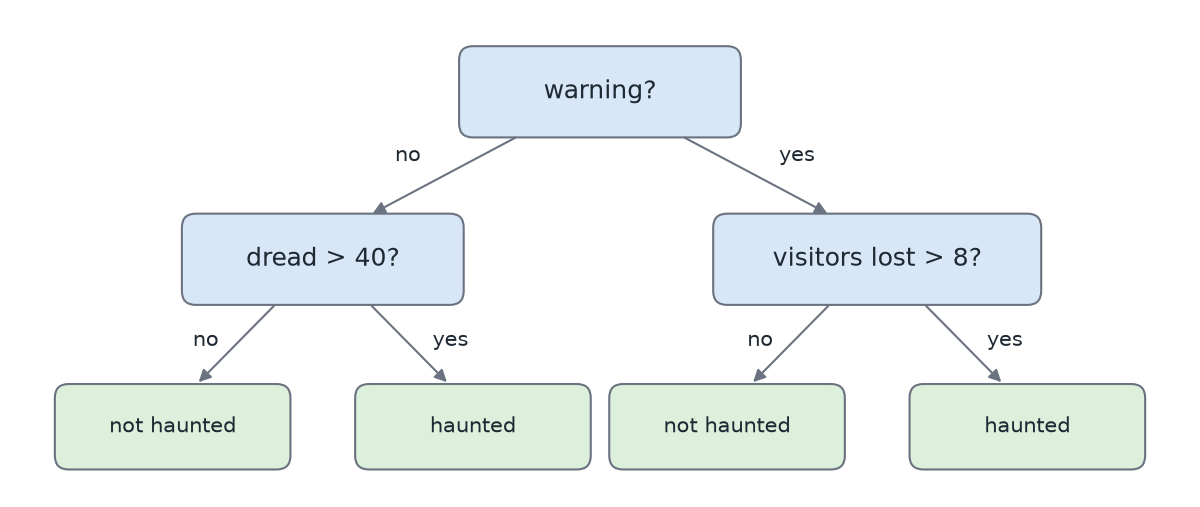

`maxDepth` is the maximum number of questions in a row. It is a **hyperparameter**: a setting we choose **before** training, unlike the questions and thresholds, which the model learns **during** training.

A deeper tree can describe finer patterns, but it can also start to learn the training rows **by heart**, including their noise and accidents. This is **overfitting**: like memorising past exams instead of understanding the subject. It shows up as a gap: very good metrics on the training set, worse metrics on the test set. The opposite problem, a model too simple to capture the pattern (bad on both sets), is called **underfitting**.

## Exercise 3 (Core): how deep should the tree be?

`DecisionTreeClassifier(featuresCol=..., labelCol=..., maxDepth=...)` creates a tree, `.fit(training)` trains it, and `evaluate_model(name, fitted_model, training, test)` scores it and records it.

**Goal:** Train four decision trees with `maxDepth` 2, 5, 10 and 20, and evaluate each one. Name each model exactly `"Decision Tree (depth N)"`, with its depth in place of N: the plot after the exercise uses these names.

**Concepts:** `DecisionTreeClassifier`, `maxDepth`, `.fit()`, `evaluate_model()`, a `for` loop over a list of depths, an f-string for the name

**Expected output:** four evaluations. As the depth grows, the train AUC climbs towards 1.0, while the test AUC stops improving and then falls. Look carefully at the confusion matrix of the depth-2 tree.

In [ ]:
from pyspark.ml.classification import DecisionTreeClassifier

# Step 1 -- Loop over the depths [2, 5, 10, 20].
# Step 2 -- Inside the loop, create a DecisionTreeClassifier with featuresCol="features",
#           labelCol=TARGET and maxDepth set to the current depth.
# Step 3 -- Fit it on `training`.
# Step 4 -- Call evaluate_model() with the name f"Decision Tree (depth {depth})",
#           the fitted model, `training` and `test`.

### 10.3 Seeing overfitting

The plot below reads the trees from the `results` table and draws their training and test AUC against the depth. The dashed line is the test AUC of the logistic regression, for reference.

In [ ]:
# 10.3 Training vs test AUC for each tree depth
import re

tree_auc = {}
for name, test_auc, test_f1, test_recall, train_auc, train_f1 in results:
    m = re.fullmatch(r"Decision Tree \(depth (\d+)\)", name)
    if m:
        tree_auc[int(m.group(1))] = (train_auc, test_auc)   # a re-run replaces the older value

if not tree_auc:
    print('No trees found: name them "Decision Tree (depth N)" in Exercise 3.')
else:
    depths = sorted(tree_auc)
    train_vals = [tree_auc[d][0] for d in depths]
    test_vals = [tree_auc[d][1] for d in depths]
    lr_test_auc = results[0][1]

    fig, ax = plt.subplots(figsize=(8, 4.5))
    ax.fill_between(depths, test_vals, train_vals, color="#E9EAEC", label="gap (overfitting)")
    ax.plot(depths, train_vals, "o-", color="#3B6FB6", label="training AUC")
    ax.plot(depths, test_vals, "o-", color="#3E8E5A", label="test AUC")
    ax.axhline(lr_test_auc, color="#6B7280", ls="--", lw=1, label="logistic regression (test)")
    ax.set_xticks(depths)
    ax.set_xlabel("maxDepth")
    ax.set_ylabel("AUC")
    ax.spines[["top", "right"]].set_visible(False)
    ax.legend(frameon=False)
    plt.show()

What should you notice?
- The blue line (training) keeps rising: a deep enough tree can fit the training rows almost perfectly
- The green line (test) does not follow: after a point, extra depth makes the test results worse. The growing grey area is overfitting
- The best depth is where the test line is highest, not where the training line is

Discussion:
- What does the depth-2 tree predict for (almost) every property? What is its accuracy, and what is its recall? Compare with Exercise 1. Is it overfitting or underfitting?
- What is the depth-20 tree learning that does not work on new properties?

### 10.4 Ensemble methods: random forests and gradient-boosted trees

One investigator can be fooled; a panel of investigators is harder to fool. **Ensemble methods** combine many models into one. A **random forest** trains many trees, each on a random sample of the rows and of the features, and lets them vote:

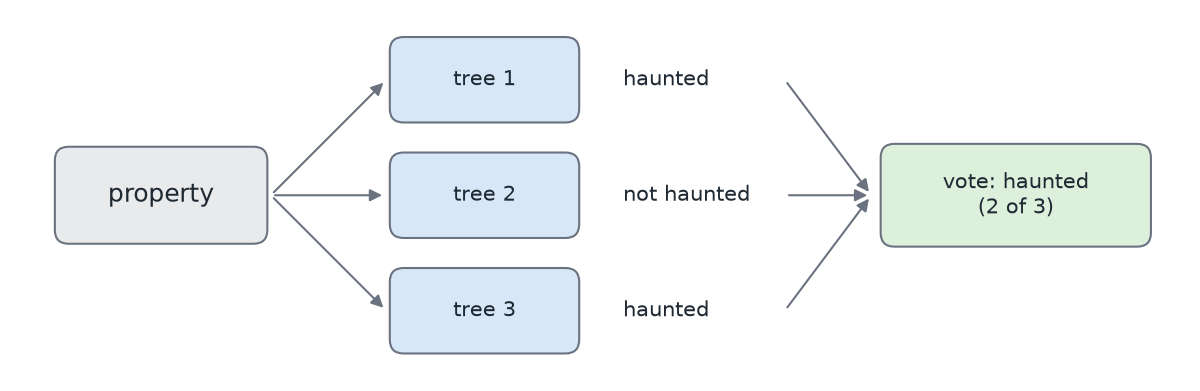

Because each tree sees slightly different data, their individual mistakes partly cancel out in the vote, which reduces overfitting.

**Gradient-boosted trees (GBT)** also use many small trees, but build them one after another: each new tree concentrates on the properties the previous trees got wrong. `maxIter` is the number of trees, and `stepSize` (the **learning rate**) is how strongly each new tree corrects the previous ones: small steps are more careful but need more trees.

## Exercise 4 (Practice): random forest

`RandomForestClassifier` takes the same `featuresCol` and `labelCol` as the tree, plus the hyperparameters `numTrees` (how many trees vote) and `maxDepth` (how deep each tree is). `seed` makes the random sampling repeatable.

**Goal:** Train a random forest with `numTrees=100`, `maxDepth=5`, `seed=42` and evaluate it. Then train and evaluate one more forest with different settings of your choice (for example `numTrees=20, maxDepth=10`).

**Concepts:** `RandomForestClassifier`, `numTrees`, `maxDepth`, `seed`, `.fit()`, `evaluate_model()`

**Expected output:** two evaluations. Compare the first forest with the single tree of depth 5: is the test AUC higher? Is the recall?

In [ ]:
from pyspark.ml.classification import RandomForestClassifier

# Step 1 -- Create a RandomForestClassifier (featuresCol, labelCol, numTrees=100, maxDepth=5, seed=42).
# Step 2 -- Fit it on `training`.
# Step 3 -- Evaluate it with evaluate_model(), name "Random Forest (100 trees, depth 5)".
# Step 4 -- Repeat steps 1-3 with other settings, and a name that says which.

## Exercise 5 (Practice): gradient-boosted trees

`GBTClassifier` takes `featuresCol`, `labelCol` and the hyperparameters `maxIter` (number of trees), `maxDepth` (depth of each tree), `stepSize` (learning rate) and `seed`.

**Goal:** Train a GBT with `maxIter=50`, `maxDepth=3`, `stepSize=0.05`, `seed=42` and evaluate it. Then halve `stepSize` and double `maxIter` (`stepSize=0.025`, `maxIter=100`) and evaluate again.

**Concepts:** `GBTClassifier`, `maxIter`, `maxDepth`, `stepSize`, `seed`, `.fit()`, `evaluate_model()`

**Expected output:** two evaluations. Compare their test AUC and recall, and notice that the second one takes longer to train.

In [ ]:
from pyspark.ml.classification import GBTClassifier

# Step 1 -- Create a GBTClassifier (featuresCol, labelCol, maxIter=50, maxDepth=3, stepSize=0.05, seed=42).
# Step 2 -- Fit it on `training` and evaluate it, name "GBT (50 trees, step 0.05)".
# Step 3 -- Repeat with maxIter=100 and stepSize=0.025, name "GBT (100 trees, step 0.025)".

### 10.5 All models side by side

In [ ]:
# 10.5 Summary table, best test AUC first
summary_df = spark.createDataFrame(
    results, ["model", "test_auc", "test_f1_macro", "test_recall", "train_auc", "train_f1_macro"]
)
summary_df.select(
    "model", *[F.round(c, 3).alias(c) for c in summary_df.columns[1:]]
).orderBy(F.desc("test_auc")).show(truncate=False)

Discussion:
- Which model would you hand to HMSPIA? The one with the best test AUC, or the one with the best recall?
- Which models show the biggest gap between train and test?
- Every label in this table was decided by an investigator. What happens to all our metrics if some of those decisions were wrong?
- Would this still work with 100 million properties? Which steps would get slower?

___

## 11) Experiment tracking with MLflow

Every `evaluate_model()` call above was recorded as an MLflow run. The cell below reads them back as a table, best test AUC first; the Experiments panel shows the same runs and can plot them against each other (for example test AUC against `maxDepth`).

In [ ]:
# 11.1 All runs of the experiment
exp = mlflow.get_experiment_by_name(EXPERIMENT_NAME)
runs_df = mlflow.search_runs(experiment_ids=[exp.experiment_id],
                             order_by=["metrics.test_auc DESC"])

cols = ["tags.mlflow.runName", "metrics.train_auc", "metrics.test_auc",
        "metrics.test_recall", "params.maxDepth", "params.numTrees",
        "params.maxIter", "params.stepSize"]
display(runs_df[[c for c in cols if c in runs_df.columns]])

> If you re-run cells, the same model is recorded again as a new run. That is fine: MLflow keeps the full history.

___

## 12) Summary

- Classification: learn rules from examples with a known label, then predict the label of new rows
- EDA comes first: missing values, imbalanced classes, outliers, correlations and multicollinearity
- Feature engineering turns every feature into numbers: new features, 1/0 flags, one-hot encoding for nominal categories
- Feature scaling (standardisation) puts numeric features on a common scale; it matters for logistic regression, not for trees
- Spark ML works with two verbs: `.fit()` learns, `.transform()` applies; all features go into one feature vector
- Always grade a model on a test set it has never seen
- The confusion matrix counts right and wrong guesses; with imbalanced data, accuracy alone is misleading, so also look at recall, precision, F1 and AUC
- Hyperparameters are chosen before training; too much depth leads to overfitting (train metrics improve while test metrics get worse)
- Ensemble methods (random forest, GBT) combine many trees and are usually more reliable than one
- MLflow records every model with its settings and metrics

Next week: ML pipelines, which chain all the preparation steps and the model into one reusable recipe.

___

## 13) Optional challenge: classifying text with TF-IDF

> **This section is optional and not part of the class.** It is for students who want to go further on their own, in particular those working with the Mental Health text dataset in the project, where each social media text has to be classified into one of six emotions. Work through it at your own pace, and use the reading list to understand each step.

So far we ignored the four free-text columns (`estate_agent_euphemism`, `cat_behaviour`, `vicar_response`, `most_recent_excuse`). Here we use **only** these texts:
- **Part A:** predict `haunted` (2 classes) from the text
- **Part B:** predict `phenomenon_type` (18 classes) from the text. This is **multiclass** classification, the same kind of task as classifying emotions

### 13.1 From text to numbers

A model needs numbers, so each text must become a vector. The classic approach is a **bag of words**: forget the word order and describe each text by which words it contains and how often.

1. **Tokenization** (`Tokenizer`): split each text into lowercase words (*tokens*). `"The cat sits facing the wall"` becomes `["the", "cat", "sits", "facing", "the", "wall"]`
2. **Stop words** (`StopWordsRemover`, optional): remove very common words ("the", "and", "of") that appear everywhere and say little
3. **Term frequency, TF** (`HashingTF`): count how often each word appears in each text. Instead of keeping a dictionary of all words, `HashingTF` sends each word to one of a fixed number of buckets (here 512) with a hash function (the **hashing trick**). It is fast and memory-safe, but two different words can occasionally share a bucket. `CountVectorizer` is the alternative that keeps a real vocabulary
4. **Inverse document frequency, IDF** (`IDF`): give less weight to words that appear in many texts and more weight to rare, distinctive words. Spark uses `idf = log((N + 1) / (df + 1))`, where N is the number of texts and df the number of texts containing the word. A word present in every text gets a weight close to 0

**TF-IDF** = TF x IDF: a word scores high in a text if it is frequent **in that text** but rare **in the others**. As in one-hot encoding, most positions are 0, so the result is a sparse vector.

The cell below builds the TF-IDF features for the four columns and assembles them into one `features` vector. It keeps both labels: `haunted` and `phenomenon_idx` (the numeric version of `phenomenon_type` from section 5.2).

In [ ]:
# 13.1 Text-only features with TF-IDF
from pyspark.ml.feature import Tokenizer, HashingTF, IDF

TEXT_COLS = ["estate_agent_euphemism", "cat_behaviour", "vicar_response", "most_recent_excuse"]

data_text = properties.select(TEXT_COLS + [TARGET, "phenomenon_type", "phenomenon_idx"])
tfidf_cols = []
for tc in TEXT_COLS:
    data_text = Tokenizer(inputCol=tc, outputCol=f"{tc}_tokens").transform(data_text)
    data_text = HashingTF(inputCol=f"{tc}_tokens", outputCol=f"{tc}_tf",
                          numFeatures=512).transform(data_text)
    data_text = IDF(inputCol=f"{tc}_tf", outputCol=f"{tc}_tfidf",
                    minDocFreq=5).fit(data_text).transform(data_text)   # ignore words in fewer than 5 texts
    tfidf_cols.append(f"{tc}_tfidf")

data_text_only = VectorAssembler(inputCols=tfidf_cols, outputCol="features") \
    .transform(data_text).select("features", TARGET, "phenomenon_type", "phenomenon_idx")

data_text.select("cat_behaviour", "cat_behaviour_tokens").show(2, truncate=60)
print("Text-only feature vector:", data_text_only.first()["features"].size, "positions")

## Exercise 6 (Challenge (optional)): Part A, is it haunted? (text only)

**Goal:** Split `data_text_only` 70/30 with `seed=42`, train a GBT with the settings of the first model of Exercise 5, and evaluate it with `evaluate_model()` as `"GBT (text only)"`. Then re-run the summary table of 10.5.

**Concepts:** `randomSplit()`, `GBTClassifier`, `.fit()`, `evaluate_model()`

**Expected output:** one more evaluation and one more row in the summary table. Compare its test AUC and recall with the models that used the structured columns.

In [ ]:
from pyspark.ml.classification import GBTClassifier

# Step 1 -- Split data_text_only into training_text and test_text (70/30, seed=42).
# Step 2 -- Create a GBTClassifier with maxIter=50, maxDepth=3, stepSize=0.05, seed=42.
# Step 3 -- Fit it on training_text and evaluate it with evaluate_model(), name "GBT (text only)".
# Step 4 -- Re-run the summary table cell of 10.5.

## Exercise 7 (Challenge (optional)): Part B, which phenomenon? (multiclass)

With more than two classes a few things change:
- Not every model can do it: in Spark, `GBTClassifier` only handles two classes, while `LogisticRegression` (in its *multinomial* form, chosen automatically) and `RandomForestClassifier` handle many
- The confusion matrix becomes 18 x 18, and there is no single "positive" class, so recall and precision are computed **for each class**
- `MulticlassClassificationEvaluator` gives `accuracy` and `f1` (the F1 of each class, averaged with weights by class size). F1 for one class at a time is available with `metricName="fMeasureByLabel"` and `metricLabel=<class index>`
- The baseline is no longer 50%: guessing at random among 18 classes is right about 6% of the time, and always answering the most common class about 11%

**Goal:** Using the same split as Part A, train a `LogisticRegression` with `labelCol="phenomenon_idx"` on the text features, compute its test accuracy and F1 with `MulticlassClassificationEvaluator`, and compare them with the baselines above. Then look at the 18 x 18 confusion matrix: which phenomena does the model confuse with each other?

**Concepts:** `LogisticRegression` (multinomial), `MulticlassClassificationEvaluator`, `groupBy().pivot()` for the confusion matrix

**Expected output:** an accuracy and an F1 far above the baselines, and a confusion matrix with most counts on the diagonal.

In [ ]:
from pyspark.ml.evaluation import MulticlassClassificationEvaluator

# Step 1 -- Create a LogisticRegression with featuresCol="features", labelCol="phenomenon_idx", maxIter=50.
# Step 2 -- Fit it on training_text and transform test_text.
# Step 3 -- Evaluate the predictions with MulticlassClassificationEvaluator(labelCol="phenomenon_idx",
#           metricName="accuracy"), and again with metricName="f1".
# Step 4 -- Confusion matrix: group the predictions by "phenomenon_idx", pivot on "prediction",
#           count, fill nulls with 0, order by "phenomenon_idx" and show.
# Step 5 (extra) -- Try a RandomForestClassifier, or add StopWordsRemover to 13.1, and compare.

Discussion: the texts were written by estate agents, vicars and owners, often **after** the investigation. If a text-only model scores well, is it predicting the phenomenon, or reading the investigators' conclusions back from the descriptions? In the Mental Health dataset, what could make a text look like one emotion while the author felt another?

### Reading list

- Spark documentation, feature extraction (Tokenizer, StopWordsRemover, HashingTF, CountVectorizer, IDF): https://spark.apache.org/docs/latest/ml-features.html
- Spark documentation, classification models (including multinomial logistic regression): https://spark.apache.org/docs/latest/ml-classification-regression.html
- Jurafsky and Martin, *Speech and Language Processing* (free online book), chapter on vector semantics, sections on TF-IDF: https://web.stanford.edu/~jurafsky/slp3/
- scikit-learn user guide, text feature extraction (clear explanations with small examples; the ideas are the same in Spark): https://scikit-learn.org/stable/modules/feature_extraction.html#text-feature-extraction